# SC03 Student Performance and Academic Intervention System
## Step 3: Build and Train an Artificial Neural Network (ANN)

This notebook follows the Step 3 beginner click-by-click guide adapted for SC03:
1. Load and inspect prepared Step 2 splits (`train.csv`, `validation.csv`, `test.csv`).
2. Build an ANN pipeline with feature scaling (`StandardScaler`) and multi-layer perceptron (`MLPClassifier`).
3. Train the feed-forward ANN using backpropagation with early stopping.
4. Evaluate validation and test metrics (Accuracy, Precision, Recall, Macro F1).
5. Plot the training loss curve and labelled confusion matrices.
6. Save trained model artifacts, predictions, and metadata evidence.


In [1]:
from pathlib import Path
import json
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "data" / "reports"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for folder in [REPORT_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "attendance_pct",
    "assessment_pct",
    "assignment_pct",
    "engagement_score",
    "prior_performance_pct",
]
TARGET = "risk_label"
RANDOM_SEED = 42

print(f"Project folder: {PROJECT_ROOT}")


Project folder: C:\Users\Abhishek\Capstone Project


In [2]:
def load_split(name):
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Cannot find {path}. Complete Step 2 first.")
    frame = pd.read_csv(path)
    required = FEATURES + [TARGET]
    if frame[required].isna().sum().sum() != 0:
        raise ValueError(f"{name}.csv still has missing values.")
    return frame


In [3]:
train_data = load_split("train")
validation_data = load_split("validation")
test_data = load_split("test")

for name, frame in [("Train", train_data), ("Validation", validation_data), ("Test", test_data)]:
    print(f"\n{name}: {frame.shape[0]} rows, {frame.shape[1]} columns")
    print(frame[TARGET].value_counts(normalize=True).round(3))

train_data.head()



Train: 8400 rows, 7 columns
risk_label
low       0.445
high      0.294
medium    0.261
Name: proportion, dtype: float64

Validation: 1800 rows, 7 columns
risk_label
low       0.445
high      0.294
medium    0.261
Name: proportion, dtype: float64

Test: 1800 rows, 7 columns
risk_label
low       0.445
high      0.294
medium    0.261
Name: proportion, dtype: float64


,record_id,attendance_pct,assessment_pct,assignment_pct,engagement_score,prior_performance_pct,risk_label
0,STU-11928,42.1,37.3,48.2,2.3,60.2,high
1,STU-05091,89.3,84.6,79.4,8.4,87.7,low
2,STU-09536,41.6,28.5,44.9,3.1,72.3,high
3,STU-03235,68.0,63.1,67.5,5.2,50.8,medium
4,STU-03874,69.8,58.9,64.3,5.4,26.0,medium


In [4]:
X_train, y_train = train_data[FEATURES], train_data[TARGET]
X_validation, y_validation = validation_data[FEATURES], validation_data[TARGET]
X_test, y_test = test_data[FEATURES], test_data[TARGET]
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")


X_train shape: (8400, 5)
y_train shape: (8400,)


In [5]:
ann_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "ann",
            MLPClassifier(
                hidden_layer_sizes=(16, 8),
                activation="relu",
                solver="adam",
                learning_rate_init=0.001,
                max_iter=400,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=25,
                random_state=RANDOM_SEED,
            ),
        ),
    ]
)

print("ANN architecture: 5 inputs -> 16 -> 8 -> 3 output classes")
ann_model


ANN architecture: 5 inputs -> 16 -> 8 -> 3 output classes


Pipeline(steps=[('scaler', StandardScaler()),
                ('ann',
                 MLPClassifier(early_stopping=True, hidden_layer_sizes=(16, 8),
                               max_iter=400, n_iter_no_change=25,
                               random_state=42, validation_fraction=0.15))])

In [6]:
ann_model.fit(X_train, y_train)
trained_ann = ann_model.named_steps["ann"]
print(f"Training iterations completed: {trained_ann.n_iter_}")
print(f"Final training loss: {round(trained_ann.loss_, 5)}")


Training iterations completed: 79
Final training loss: 0.36699


In [7]:
def metric_row(y_true, y_pred, split_name):
    return {
        "split": split_name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "f1_score": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    }

validation_predictions = ann_model.predict(X_validation)
validation_metrics = metric_row(y_validation, validation_predictions, "validation")
pd.DataFrame([validation_metrics])


,split,accuracy,precision,recall,f1_score
0,validation,0.8494,0.8351,0.8354,0.8352


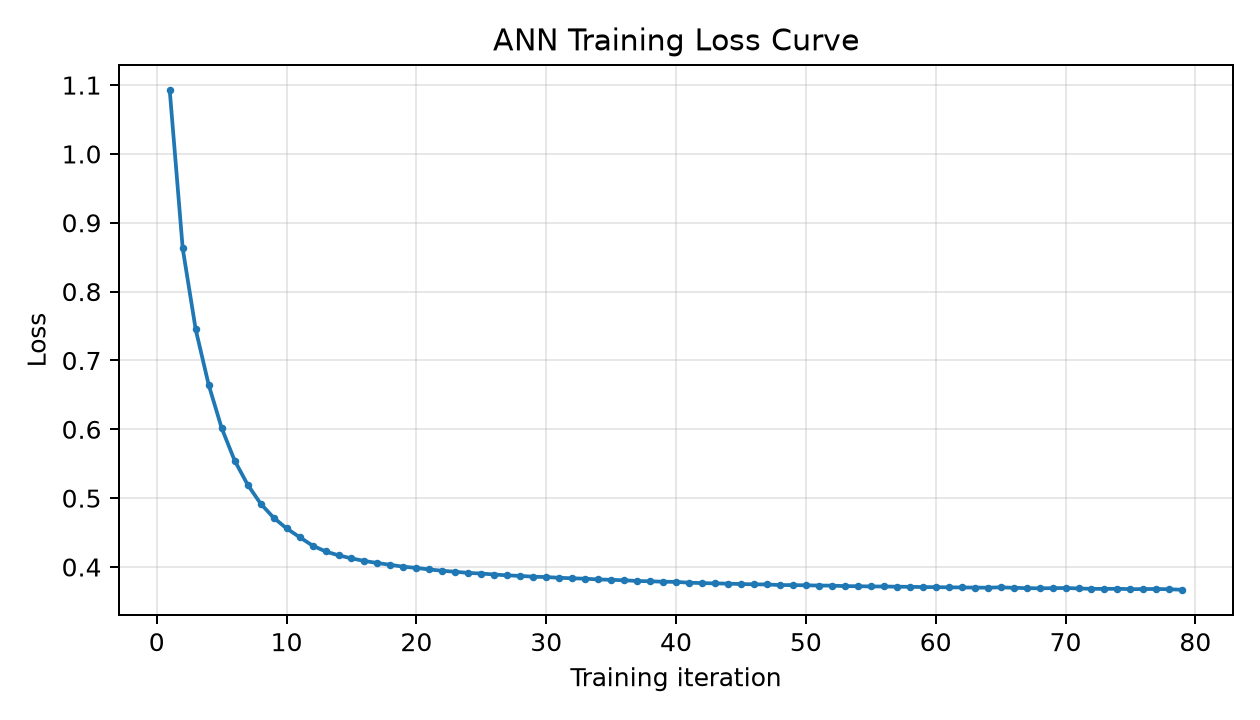

In [8]:
losses = trained_ann.loss_curve_
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(losses) + 1), losses, marker="o", markersize=2, color="#1f77b4")
plt.title("ANN Training Loss Curve")
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "step3_ann_loss_curve.png", dpi=180)
plt.show()


In [9]:
def show_confusion_matrix(y_true, y_pred, split_name):
    labels = ["low", "medium", "high"]
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    figure, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(matrix, cmap="Blues")
    figure.colorbar(image, ax=axis)
    axis.set(
        title=f"ANN Confusion Matrix - {split_name.title()} Split",
        xlabel="Predicted label",
        ylabel="Actual label",
        xticks=[0, 1, 2],
        yticks=[0, 1, 2],
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"],
    )
    for row in range(3):
        for column in range(3):
            val = matrix[row, column]
            color = "white" if val > matrix.max() / 2 else "black"
            axis.text(column, row, str(val), ha="center", va="center", color=color, fontweight="bold")
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / f"step3_{split_name}_confusion_matrix.png", dpi=180)
    plt.show()


,split,accuracy,precision,recall,f1_score
0,validation,0.8494,0.8351,0.8354,0.8352
1,test,0.8411,0.8287,0.8294,0.8290


Validation report:
               precision    recall  f1-score   support

        high       0.88      0.88      0.88       529
         low       0.91      0.90      0.91       801
      medium       0.71      0.72      0.72       470

    accuracy                           0.85      1800
   macro avg       0.84      0.84      0.84      1800
weighted avg       0.85      0.85      0.85      1800


Test report:
               precision    recall  f1-score   support

        high       0.90      0.89      0.90       529
         low       0.89      0.88      0.89       801
      medium       0.69      0.71      0.70       470

    accuracy                           0.84      1800
   macro avg       0.83      0.83      0.83      1800
weighted avg       0.84      0.84      0.84      1800


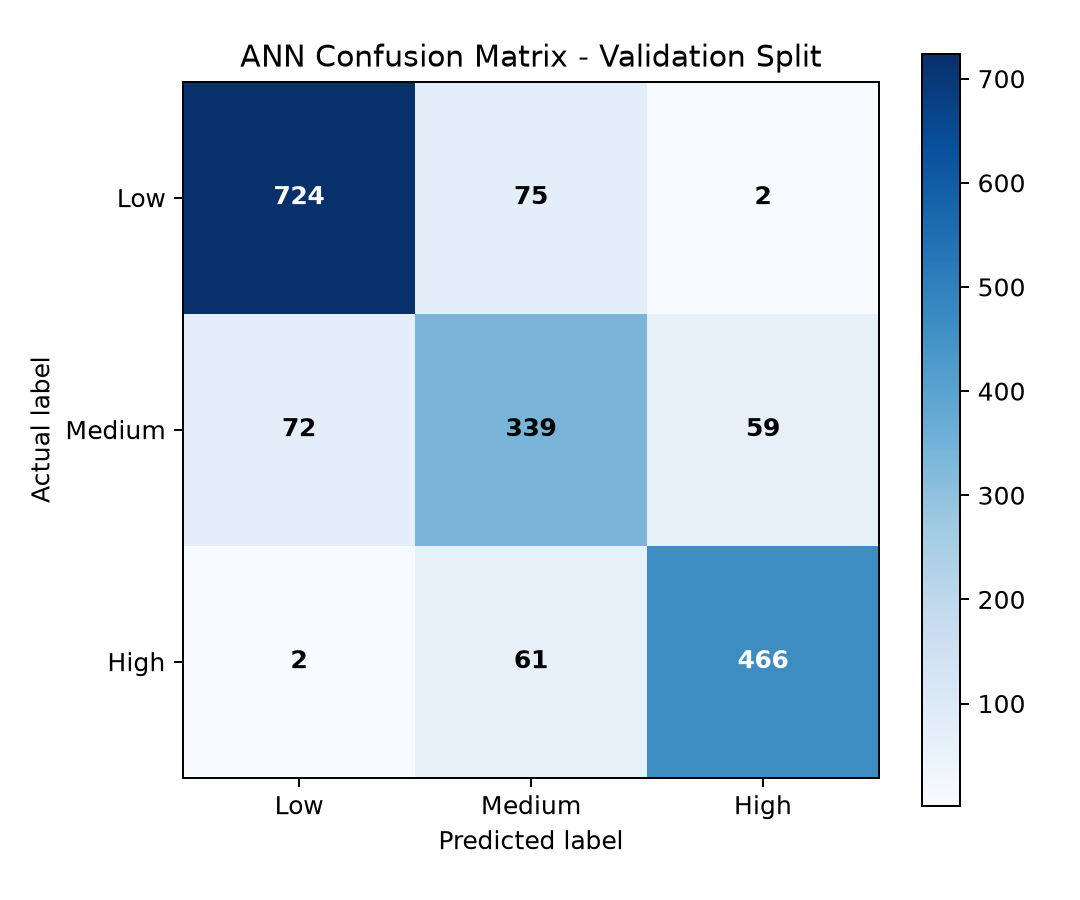

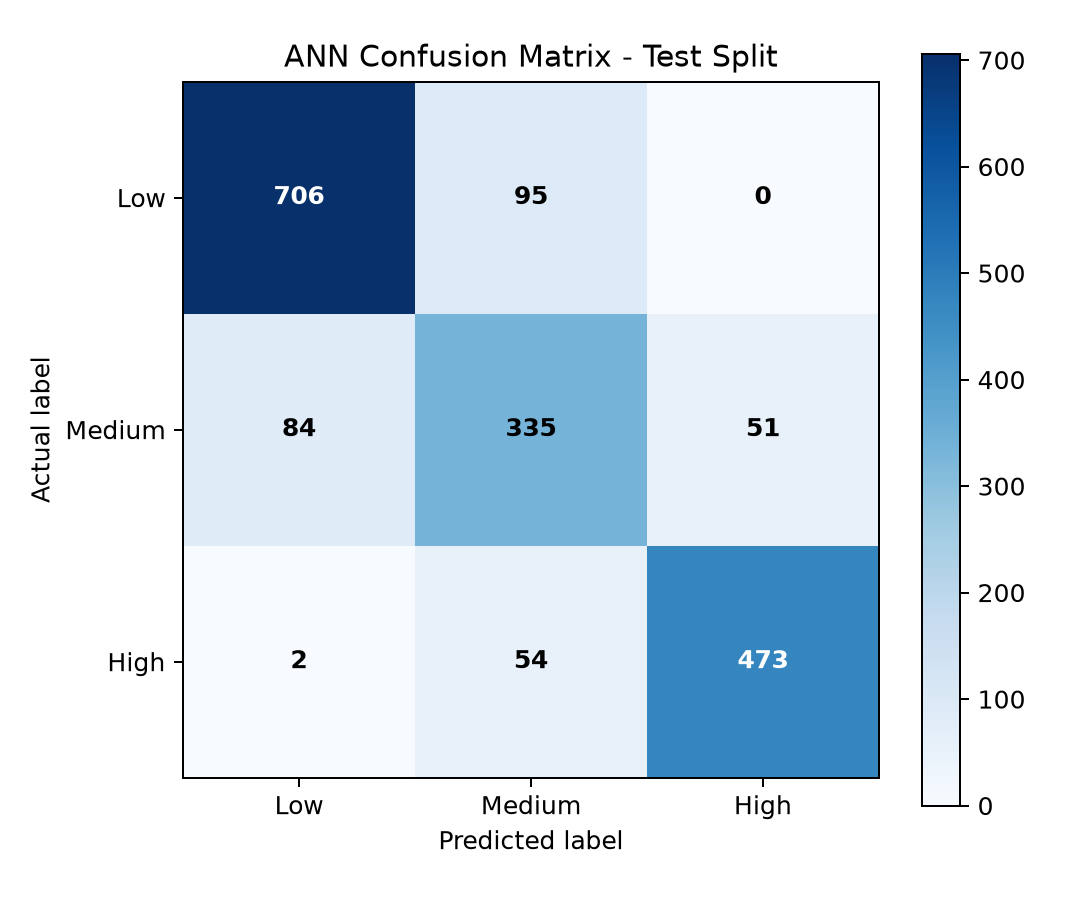

In [10]:
test_predictions = ann_model.predict(X_test)
test_metrics = metric_row(y_test, test_predictions, "test")
metrics = pd.DataFrame([validation_metrics, test_metrics])
display(metrics)

print("Validation report:\n", classification_report(y_validation, validation_predictions, zero_division=0))
print("\nTest report:\n", classification_report(y_test, test_predictions, zero_division=0))

show_confusion_matrix(y_validation, validation_predictions, "validation")
show_confusion_matrix(y_test, test_predictions, "test")


In [11]:
metrics.to_csv(REPORT_DIR / "step3_ann_metrics.csv", index=False)

for split_name, frame, predictions in [
    ("validation", validation_data, validation_predictions),
    ("test", test_data, test_predictions),
]:
    output = frame.copy()
    output["ann_prediction"] = predictions
    probs = ann_model.predict_proba(frame[FEATURES])
    for idx, cls_name in enumerate(ann_model.classes_):
        output[f"prob_{cls_name}"] = probs[:, idx].round(4)
    output.to_csv(REPORT_DIR / f"step3_{split_name}_predictions.csv", index=False)

with (MODEL_DIR / "ann_student_performance.pkl").open("wb") as model_file:
    pickle.dump(ann_model, model_file)

with (MODEL_DIR / "ann_model.pkl").open("wb") as model_file:
    pickle.dump(ann_model, model_file)

metadata = {
    "technique": "feed-forward ANN / backpropagation (scikit-learn MLPClassifier)",
    "architecture": "5 inputs -> 16 hidden neurons -> 8 hidden neurons -> 3 output neurons (Softmax)",
    "features": FEATURES,
    "target": TARGET,
    "classes": list(ann_model.classes_),
    "random_seed": RANDOM_SEED,
    "training_iterations": int(trained_ann.n_iter_),
    "final_loss": round(float(trained_ann.loss_), 5),
    "validation_accuracy": float(validation_metrics["accuracy"]),
    "validation_macro_f1": float(validation_metrics["f1_score"]),
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_macro_f1": float(test_metrics["f1_score"]),
}

(MODEL_DIR / "ann_model_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("Saved model and Step 3 evidence files.")


Saved model and Step 3 evidence files.
